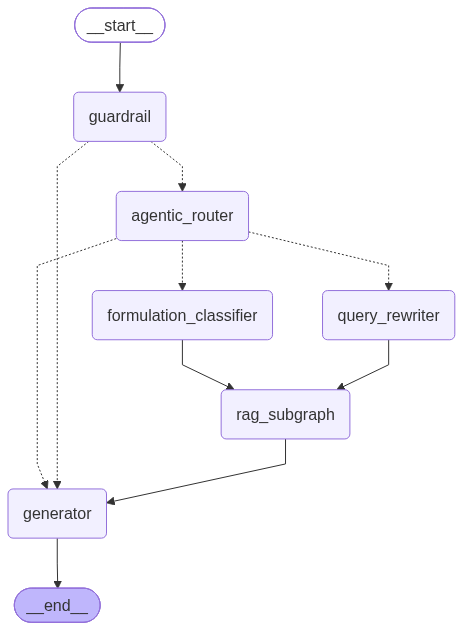

In [3]:
"""Main LangGraph Workflow for IP-SAKTI Sahayak."""
from langgraph.graph import StateGraph, START, END
from core.state import GraphState
from nodes.guardrail import guardrail_assessor_node
from nodes.router import agentic_router_node
from nodes.query_rewriter import query_rewriter_node
from nodes.classifier import formulation_classifier_node
from nodes.generator import generator_node
from subgraphs.rag_subgraph import create_rag_subgraph

# conditional edge routers
def route_guardrail(state: GraphState) -> str:
    """Conditional edge after guardrail assessment."""
    if not state.get("is_safe", True):
        return "generator" # return to END
    return "agentic_router"

def route_split(state: GraphState) -> str:
    """Conditional edge for the 3-way split."""
    route = state.get("route_path", "path_a")
    if route == "path_a":
        return "generator"
    elif route == "path_b":
        return "query_rewriter"
    elif route == "path_c":
        return "formulation_classifier"
    return "generator"

def route_classifier(state: GraphState) -> str:
    """Check if clarification questions are needed or ready for RAG."""
    if state.get("needs_clarification", False):
        return END  # Pauses/yields questions to the user (introduce INTERRUPT/Commands here)
    return "rag_subgraph"

def build_graph() -> StateGraph:
    """Constructs and compiles the complete IP-SAKTI Sahayak LangGraph."""
    workflow = StateGraph(GraphState)

    # 1. Add Gatekeeper Nodes
    workflow.add_node("guardrail", guardrail_assessor_node)
    workflow.add_node("agentic_router", agentic_router_node)

    # 2. Add Branch Nodes
    workflow.add_node("query_rewriter", query_rewriter_node)
    workflow.add_node("formulation_classifier", formulation_classifier_node)

    # 3. Add RAG Subgraph & Generator
    rag_subgraph = create_rag_subgraph()
    workflow.add_node("rag_subgraph", rag_subgraph)
    workflow.add_node("generator", generator_node)

    # 4. Define Workflow Edges
    workflow.add_edge(START, "guardrail")

    workflow.add_conditional_edges(
        "guardrail",
        route_guardrail,
        {
            "agentic_router": "agentic_router",
            "generator": "generator",
        }
    )

    workflow.add_conditional_edges(
        "agentic_router",
        route_split,
        {
            "generator": "generator",
            "query_rewriter": "query_rewriter",
            "formulation_classifier": "formulation_classifier"
        }
    )

    workflow.add_edge("query_rewriter", "rag_subgraph")
    
    # fix to go directly from formulation_classifier to rag_subgraph
    # workflow.add_conditional_edges(
    #     "formulation_classifier",
    #     route_classifier,
    #     {
    #         END: END,
    #         "rag_subgraph": "rag_subgraph"
    #     }
    # )
    workflow.add_edge("formulation_classifier", "rag_subgraph")

    workflow.add_edge("rag_subgraph", "generator")
    workflow.add_edge("generator", END)

    return workflow.compile()

# Precompiled instance
app = build_graph()
app